# Spatial leakage test: how should we split the data?

Nearby wells have similar nitrate levels. If a test well has close neighbors in the training data, we risk data leakage and overstating the predictive power of our model.

We use the approach found in [*Estimation of aquifer scale proportion using equal area grids: Assessment of regional scale groundwater quality*](https://agupubs.onlinelibrary.wiley.com/doi/full/10.1029/2010WR009321) to divide our map into a square grid. We then perform group k-fold splits, keeping each grid cell intact in the splitting. We evaluate the data leakage by comparing a k-nearest-neighbors model to one that outputs the training mean. Data leakage is measured by comparing the RMSE of the KNN model to that of the mean.

In [1]:
import sys
from pathlib import Path

# Find the project root and import the shared paths (also applies the projection setting in src/__init__.py)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from sklearn.model_selection import KFold, GroupKFold
from sklearn.neighbors import KNeighborsRegressor

from src import paths
from src.evaluation import splits, leakage

NITRATE_PATH = paths.NITRATE_CLEAN
FIGURES = paths.FIGURES["evaluation"]
FIGURES.mkdir(parents=True, exist_ok=True)


In [2]:
df = pd.read_csv(NITRATE_PATH, parse_dates=["gm_samp_collection_date"])
exceeds = df["nitrate_mg_L"] > leakage.THRESHOLD_MG_L

print(f"{len(df):,} samples from {df['gm_well_id'].nunique():,} wells")
print("Samples per year:", df["gm_samp_collection_date"].dt.year.value_counts().sort_index().to_dict())
print(f"Share above {leakage.THRESHOLD_MG_L} mg/L: {exceeds.mean():.1%}")


5,280 samples from 1,993 wells
Samples per year: {2022: 1455, 2023: 1298, 2024: 1252, 2025: 1275}
Share above 10 mg/L: 33.7%


In [3]:
wells = df.drop_duplicates("gm_well_id")
xy_wells = leakage.projected_xy(wells, "gm_latitude", "gm_longitude")
nearest = cKDTree(xy_wells).query(xy_wells, k=2)[0][:, 1]

print("Distance to the nearest other well (m): "
      f"25% within {np.percentile(nearest, 25):.0f}, "
      f"median {np.median(nearest):.0f}, 75% within {np.percentile(nearest, 75):.0f}")


Distance to the nearest other well (m): 25% within 20, median 194, 75% within 434


In [4]:
def folds_from(splitter, groups=None):
    """Turn a scikit-learn splitter into one fold number per row."""
    folds = np.empty(len(df), dtype=int)
    for k, (_, test) in enumerate(splitter.split(df, groups=groups)):
        folds[test] = k
    return folds

schemes = {
    "random rows": folds_from(KFold(5, shuffle=True, random_state=0)),
    "grouped by well": folds_from(GroupKFold(5), groups=df["gm_well_id"]),
}
for km in [1, 2, 5, 10, 15, 20, 25, 30, 35, 40]:
    cells = splits.assign_grid_cells(df, cell_size_m=km * 1000)["cell"]
    schemes[f"{km} km blocks"] = splits.spatial_folds(cells, exceeds)


Here, "estimated leakage" is defined as $1 - \frac{\mathrm{RMSE}_{\mathrm{KNN}}}{\mathrm{RMSE}_\mathrm{mean}}$, where $\mathrm{RMSE}_{\mathrm{KNN}}$ is the root mean squared error of the K-nearest-neighbors estimator and $\mathrm{RMSE}_{\mathrm{mean}}$ is the root mean squared error of predicting the mean. If the KNN estimator performs similarly to predicting the mean, then the estimated leakage should be approximately 0; positive values indicate that KNN is performing better. We will graph this below.

In [5]:
table = leakage.leakage_table(df, schemes, k=5)     # Comparing KNN with k=5
table.round(3)

,rmse_log_location_only,rmse_log_no_information,estimated_leakage,accuracy_location_only,accuracy_majority_class
random rows,0.487,1.212,0.598,0.931,0.661
grouped by well,0.925,1.212,0.237,0.804,0.661
1 km blocks,1.019,1.212,0.159,0.768,0.661
2 km blocks,1.113,1.212,0.082,0.737,0.661
5 km blocks,1.232,1.213,-0.016,0.694,0.661
10 km blocks,1.241,1.213,-0.023,0.686,0.661
15 km blocks,1.226,1.213,-0.011,0.697,0.661
20 km blocks,1.332,1.226,-0.086,0.689,0.661
25 km blocks,1.292,1.269,-0.018,0.645,0.661
30 km blocks,1.262,1.253,-0.007,0.629,0.661


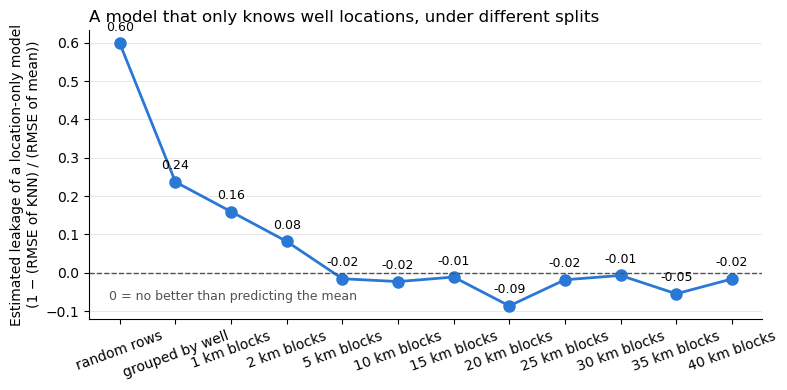

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
names = list(table.index)
ax.plot(names, table["estimated_leakage"], marker="o", color="#2a78d6", linewidth=2, markersize=8)
ax.axhline(0, color="#52514e", linewidth=1, linestyle="--")
ax.text(-0.2, -0.045, "0 = no better than predicting the mean",
        color="#52514e", fontsize=9, ha="left", va="top")
for i, s in enumerate(table["estimated_leakage"]):
    ax.annotate(f"{s:.2f}", (i, s), textcoords="offset points", xytext=(0, 9),
                ha="center", fontsize=9)

ax.set_ylabel("Estimated leakage of a location-only model\n(1 − (RMSE of KNN) / (RMSE of mean))")
ax.set_title("A model that only knows well locations, under different splits", loc="left")
ax.grid(axis="y", color="#e5e4e0", linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=20)
plt.tight_layout()
fig.savefig(FIGURES / "estimated_leakage_by_split.png", dpi=150, bbox_inches="tight")
plt.show()


- **Random rows / grouped by well:** location alone results in significant leakage. Grouping by well removes the same-well leak, but test wells still have training neighbours a few hundred metres away.
- **5–10 km blocks:** estimated leakage ≈ 0, so local copying is gone. This matches the distance at which nitrate values stop being correlated (about 5–7.5 km).
- **> 10 km blocks:** leakage appears to be uncorrelated to size. The drop at 20 km (and a smaller one at 35 km) appear to be flukes.

**Initial decision: 10 km equal-area cells.**


## Problem: original folds were unbalanced by subbasin

The 10km split balanced the share of samples above 10 mg/L in each fold, but not where the samples came from. Nitrate levels differ strongly between subbasins of the Salinas Valley, so a fold dominated by one subbasin is tested on a region that is underrepresented in its training data. This issue arose in our initial modeling experiments.

In [7]:
from src.evaluation.make_splits import load_split, SPLITS
from src.features.transformers import add_subbasin
from src.evaluation.results_log import load_runs

base = add_subbasin(df.drop(columns=["cell", "fold"], errors="ignore").astype({"gm_well_id": "string"}))
by_split = {name: load_split(base, split=name) for name in SPLITS}


def subbasin_shares(data):
    """Share of each fold's samples in each subbasin."""
    return pd.crosstab(data["fold"], data["subbasin"], normalize="index")


subbasin_shares(by_split["10km"]).round(2)


subbasin,180/400 FOOT AQUIFER,ATASCADERO AREA,EAST SIDE AQUIFER,FOREBAY AQUIFER,MONTEREY,PASO ROBLES AREA,UPPER VALLEY AQUIFER,OUTSIDE
fold,,,,,,,,
0,0.08,0.10,0.33,0.20,0.00,0.20,0.01,0.08
1,0.41,0.00,0.06,0.23,0.02,0.02,0.18,0.08
2,0.31,0.03,0.23,0.05,0.00,0.24,0.15,0.00
3,0.00,0.10,0.00,0.45,0.00,0.18,0.13,0.15
4,0.13,0.00,0.03,0.50,0.00,0.25,0.07,0.02


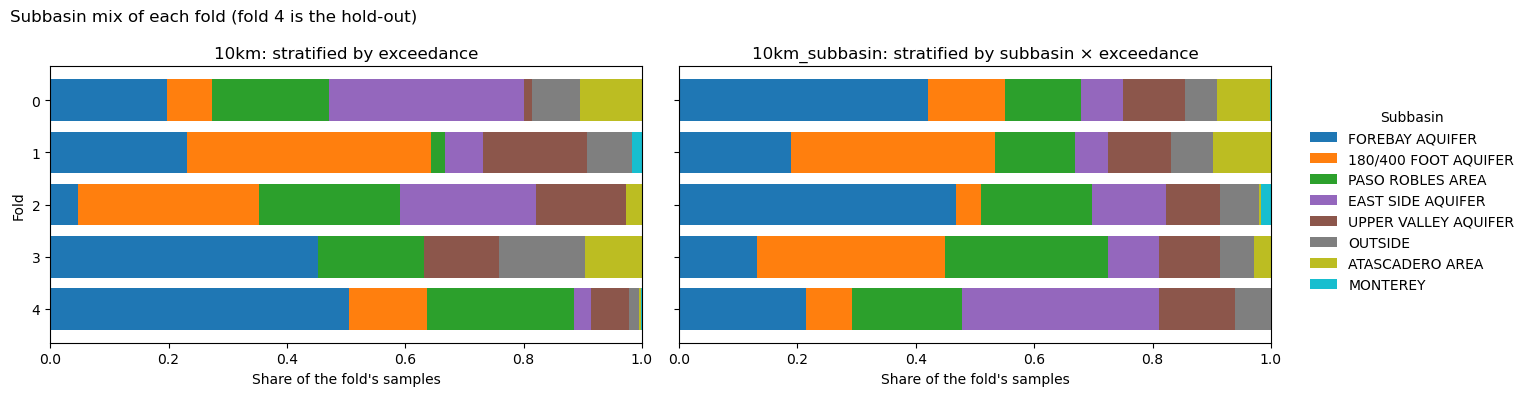

In [8]:
order = subbasin_shares(by_split["10km"]).mean().sort_values(ascending=False).index

fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, name in zip(axs, ["10km", "10km_subbasin"]):
    shares = subbasin_shares(by_split[name]).reindex(columns=order, fill_value=0)
    shares.plot.barh(stacked=True, ax=ax, legend=False, width=0.8, colormap="tab10")
    ax.set(title=f"{name}: stratified by {SPLITS[name]['stratify'].replace('_x_', ' × ')}",
           xlabel="Share of the fold's samples", ylabel="Fold", xlim=(0, 1))
    ax.invert_yaxis()
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Subbasin", loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
fig.suptitle("Subbasin mix of each fold (fold 4 is the hold-out)", x=0.01, ha="left")
plt.tight_layout()
fig.savefig(FIGURES / "subbasin_mix_by_fold.png", dpi=150, bbox_inches="tight")
plt.show()


### Consequence: model scores were unstable from fold to fold

With the original split, scores varied widely between folds and several models did worse than predicting the mean on at least one fold. Comparing the same features on the two 10km splits isolates the effect of the split.

In [9]:
runs = load_runs()
reg = runs[(runs["task"] == "regression") & ~runs["model"].str.startswith("Dummy")]

steps = [("10km", False), ("10km", True), ("10km_subbasin", True)]
rows = []
for split, use_subbasin in steps:
    part = reg[(reg["split"] == split) & (reg["use_subbasin"] == use_subbasin)]
    rows.append(part.groupby("model")["r2"].agg(["mean", "std", "min"]).add_prefix("r2_")
                    .assign(split=split, subbasin_features=use_subbasin))

(pd.concat(rows).reset_index()
   .set_index(["model", "split", "subbasin_features"]).sort_index().round(3))


r2_mean  r2_std  r2_min
model             split         subbasin_features                         
Decision tree     10km          False                0.100   0.166  -0.122
                                True                 0.271   0.069   0.210
                  10km_subbasin True                 0.220   0.058   0.141
Lasso             10km          False                0.122   0.178  -0.127
                                True                 0.161   0.193  -0.117
                  10km_subbasin True                 0.284   0.063   0.199
Linear regression 10km          False                0.065   0.244  -0.289
                                True                 0.111   0.330  -0.362
                  10km_subbasin True                 0.238   0.132   0.061
Random forest     10km          False                0.225   0.126   0.066
                                True                 0.271   0.096   0.146
                  10km_subbasin True                 0.343   0.058   0.257
Ridge             10km          False                0.129   0.159  -0.094
                                True                 0.186   0.203  -0.101
                  10km_subbasin True                 0.263   0.065   0.175
XGBoost BRT       10km          False                0.202   0.124   0.034
                                True                 0.272   0.082   0.170
                  10km_subbasin True                 0.311   0.068   0.210

### Fix: stratify by both subbasin and exceedance

StratifiedGroupKFold now balances the combined label (subbasin, above 10 mg/L), while still keeping whole grid cells together. With 10km cells there are few cells per subbasin, so we also built splits based on 7.5km and 5km grids.

In [10]:
balance = pd.DataFrame({name: splits.fold_balance(d["fold"], d["subbasin"],
                                                  d["nitrate_mg_L"] > leakage.THRESHOLD_MG_L)
                        for name, d in by_split.items()}).T
balance.insert(0, "cell_km", [SPLITS[n]["cell_size_m"] / 1000 for n in balance.index])
balance.insert(1, "stratified_by", [SPLITS[n]["stratify"] for n in balance.index])
balance


,cell_km,stratified_by,max_subbasin_deviation,exceedance_spread
10km,10.0,exceedance,0.238,0.020
5km_subbasin,5.0,subbasin_x_exceedance,0.062,0.074
7.5km_subbasin,7.5,subbasin_x_exceedance,0.115,0.124
10km_subbasin,10.0,subbasin_x_exceedance,0.201,0.159


Here, max_subbasin_deviation is the largest gap between a subbasin's share of any fold and its share of all samples, and exceedance_spread is the gap between the folds with the highest and lowest share above 10 mg/L. Lower is better for both.

In [11]:
leakage.leakage_table(base, {name: d["fold"].to_numpy() for name, d in by_split.items()}, k=5).round(3)

,rmse_log_location_only,rmse_log_no_information,estimated_leakage,accuracy_location_only,accuracy_majority_class
10km,1.241,1.213,-0.023,0.686,0.661
5km_subbasin,1.228,1.213,-0.013,0.696,0.661
7.5km_subbasin,1.239,1.217,-0.018,0.703,0.661
10km_subbasin,1.241,1.219,-0.018,0.694,0.661


We also examine the shortest distance between training and test wells for each split. 

In [12]:
def test_distances(data):
    """Distance (m) from each development sample to the nearest well in its training folds."""
    dev = data[~data["holdout"]].reset_index(drop=True)
    xy = leakage.projected_xy(dev, "gm_latitude", "gm_longitude")
    nearest_m = np.full(len(dev), np.nan)
    for train, test in splits.iter_folds(dev["fold"]):
        nearest_m[test] = leakage.nearest_training_distance(xy, train, test)
    return nearest_m


def distance_bands(distances_m):
    """Median distance (km) and the share of samples in each distance band."""
    bands = pd.Series(pd.cut(distances_m, bins=leakage.DISTANCE_BINS, labels=leakage.DISTANCE_LABELS, right=False))
    return pd.concat([pd.Series({"median_km": np.median(distances_m) / 1000}), bands.value_counts(normalize=True, sort=False)])


distance_table = pd.DataFrame({name: distance_bands(test_distances(d)) for name, d in by_split.items()}).T
distance_table.loc["any well → nearest other well"] = distance_bands(nearest)
distance_table.round(3)


,median_km,<0.5 km,0.5-1 km,1-2 km,2-5 km,>5 km
10km,3.207,0.039,0.097,0.173,0.454,0.238
5km_subbasin,1.563,0.069,0.209,0.353,0.345,0.024
7.5km_subbasin,2.117,0.042,0.151,0.283,0.470,0.055
10km_subbasin,2.580,0.039,0.114,0.229,0.474,0.144
any well → nearest other well,0.194,0.803,0.158,0.032,0.005,0.003


### Findings

In early modeling experiments, model scores varied widely from fold to fold under the original 10km split, and every linear model did worse than predicting the mean on at least one fold. Models performed worst on folds dominated by a subbasin that was underrepresented in training. Stratifying the folds by both subbasin and exceedance roughly halved the fold-to-fold standard deviation of R^2 for every model, and no model scored below the mean on any fold.

We therefore expect predictions to be most reliable within subbasins that already have monitoring wells. This aligns with our goal of identifying where additional nitrate monitoring is most needed in the Salinas Valley. Note that the model has not been tested outside the valley and should not be assumed to transfer to other regions.

Notable finds:
- There is a trade-off with balancing subbasins and balancing exceedance. The original 10km split balanced exceedance best (spread 0.020) but subbasins worst (max deviation 0.238).
- Smaller cells balance subbasins better (max deviation 0.062 for the 5km grid versus 0.201 for 10km grid), but put test wells closer to training wells (median distance to nearest training well 1.6km and 2.6km respectively for the 5km and 10km grids).
- Estimated leakage is close to zero for all four splits (-0.013 to -0.023).

**Final decision:** the 10km subbasin-stratified split. It reduces the fold-to-fold instability found in the original split while still keeping test wells far from training wells. The location-only leakage test did not detect leakage at 5km, but it is a simple test so we preferred a more conservative split. We also report the originak 10km split as a stress test for predicting in regions that are underrepresented in training.

In [13]:
from shapely.geometry import box
from src.features.transformers import SUBBASIN_PATH

# Salinas watershed (HUC8 18060005), from the same NHD geodatabase as the data cleaning notebooks
boundary = gpd.read_file(paths.HUC8_GDB, layer="WBDHU8", where="huc8 = '18060005'")
fold_colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]

boundary_ea = boundary.to_crs(splits.EQUAL_AREA_CRS)
subbasins_ea = gpd.read_file(SUBBASIN_PATH).to_crs(splits.EQUAL_AREA_CRS)



def plot_fold_map(ax, data, split):
    """Grid cells shaded by fold, wells as dots, with subbasin outlines, for one registered split."""
    size = SPLITS[split]["cell_size_m"]
    holdout = SPLITS[split]["n_splits"] - 1
    wells = data.drop_duplicates("gm_well_id")

    cells = wells.drop_duplicates("cell")[["cell", "fold"]]
    corners = cells["cell"].str.split("_", expand=True).astype(int)     # cell "x_y" -> grid indices
    squares = gpd.GeoDataFrame(
        cells, crs=splits.EQUAL_AREA_CRS,
        geometry=[box(i * size, j * size, (i + 1) * size, (j + 1) * size) for i, j in corners.itertuples(index=False)])
    points = gpd.GeoDataFrame(
        wells, crs="EPSG:4326",
        geometry=gpd.points_from_xy(wells["gm_longitude"], wells["gm_latitude"])).to_crs(splits.EQUAL_AREA_CRS)

    for k, color in enumerate(fold_colors):
        squares[squares["fold"] == k].plot(ax=ax, color=color, alpha=0.25, edgecolor=color, linewidth=0.5)
        label = f"fold {k}" + (" (hold-out)" if k == holdout else "")
        points[points["fold"] == k].plot(ax=ax, color=color, markersize=4, label=label)
    subbasins_ea.boundary.plot(ax=ax, color="black", linewidth=0.6)
    boundary_ea.boundary.plot(ax=ax, color="#52514e", linewidth=1)
    ax.set_title(f"{split}: {size / 1000:g} km cells, stratified by "
                 f"{SPLITS[split]['stratify'].replace('_x_', ' × ')}", loc="left", fontsize=10)
    ax.set_axis_off()


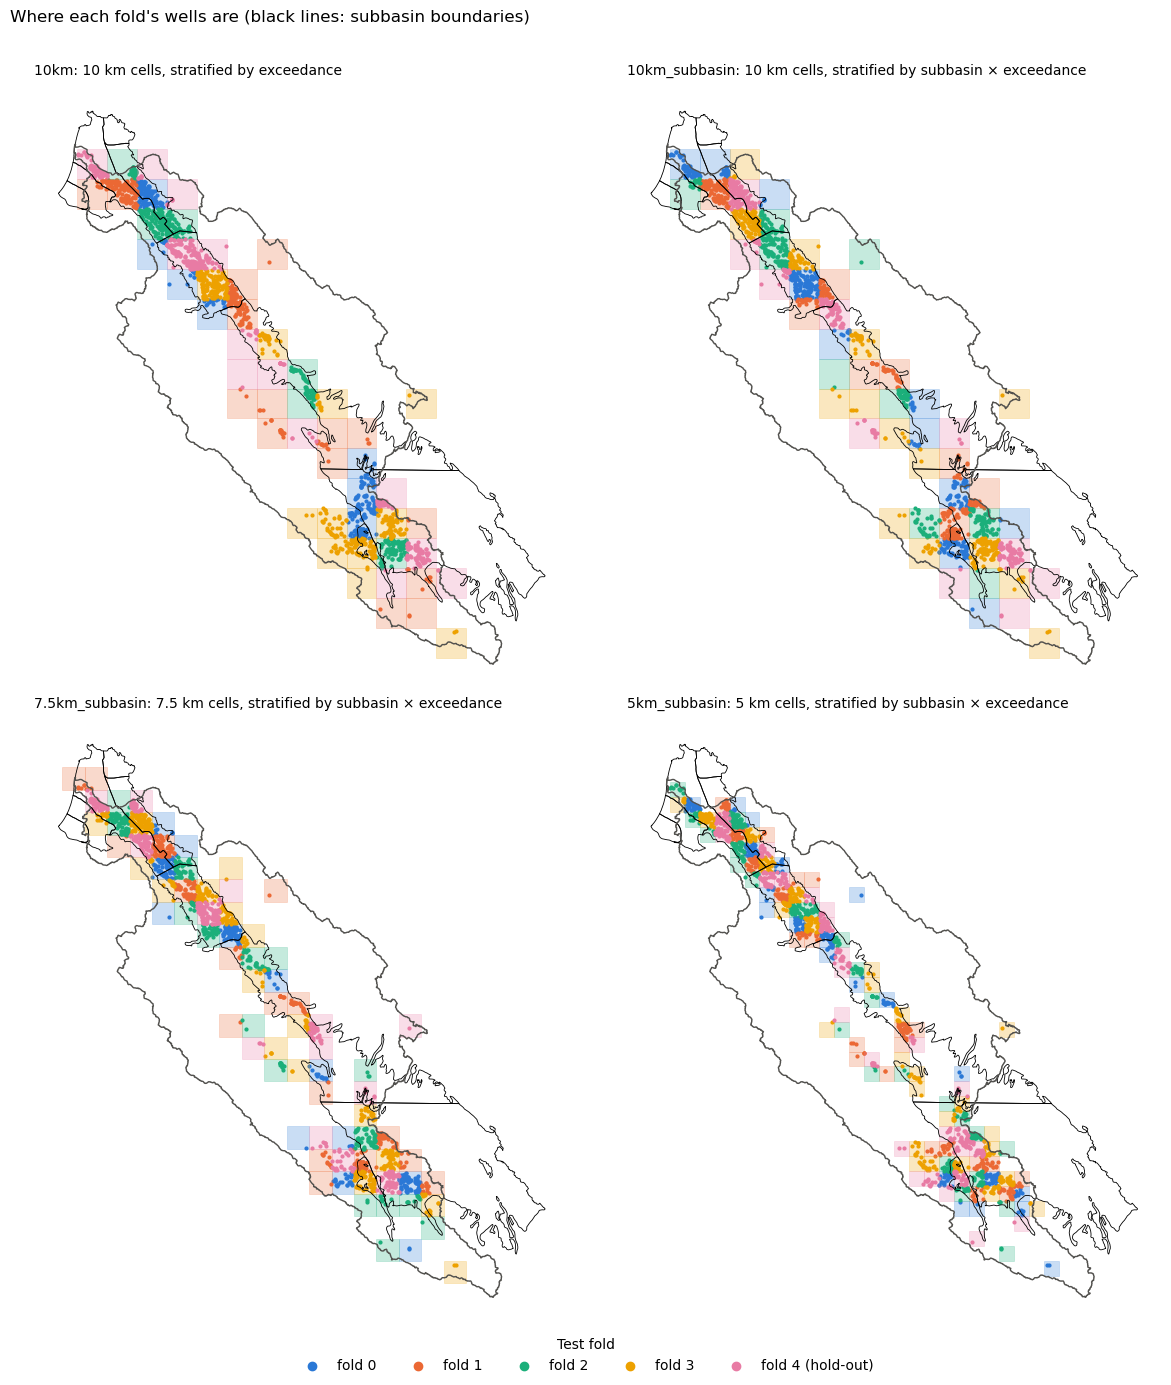

In [14]:
names = ["10km", "10km_subbasin", "7.5km_subbasin", "5km_subbasin"]

# All four splits in one figure
fig, axs = plt.subplots(2, 2, figsize=(12, 14))
for ax, name in zip(axs.ravel(), names):
    plot_fold_map(ax, by_split[name], name)
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, title="Test fold", loc="lower center", ncol=5, frameon=False, markerscale=3)
fig.suptitle("Where each fold's wells are (black lines: subbasin boundaries)", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0.03, 1, 0.97))
fig.savefig(FIGURES / "spatial_folds_maps_all_splits.png", dpi=150, bbox_inches="tight")
plt.show()

# One file per split
for name in names:
    fig, ax = plt.subplots(figsize=(7, 8))
    plot_fold_map(ax, by_split[name], name)
    ax.legend(title="Test fold", loc="upper right", frameon=False, markerscale=3)
    fig.savefig(FIGURES / f"spatial_folds_map_{name}.png", dpi=150, bbox_inches="tight")
    plt.close(fig)
